In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

abalone = fetch_ucirepo(id=1)

X = abalone.data.features
y = abalone.data.targets


print(abalone.metadata)

print(abalone.variables)

{'uci_id': 1, 'name': 'Abalone', 'repository_url': 'https://archive.ics.uci.edu/dataset/1/abalone', 'data_url': 'https://archive.ics.uci.edu/static/public/1/data.csv', 'abstract': 'Predict the age of abalone from physical measurements', 'area': 'Biology', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Tabular'], 'num_instances': 4177, 'num_features': 8, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['Rings'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C55C7W', 'creators': ['Warwick Nash', 'Tracy Sellers', 'Simon Talbot', 'Andrew Cawthorn', 'Wes Ford'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting the age of abalone from physical measurements.  The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- 

Sex (пол) - M, F, and I (infant) М, Ж, молодая особь

Length (длина) - длина самой длинной оболочки

Diameter (диаметр)

Height (высота) - с мясом в скорлупе

Whole_weight (полный вес) - цельное морское ушко

Shucked_weight (очищенный вес) - масса мяса

Viscera_weight (вес кишечника) - вес кишечника (после обескровливания)

Shell_weight (вес скорлупы) - после высыхания

Rings (кольца) - +1,5 — это возраст в годах

In [4]:
df = pd.concat([X,y], axis=1)

In [5]:
df.head(10)

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7
5,I,0.425,0.300,0.095,0.3515,0.1410,0.0775,0.120,8
6,F,0.530,0.415,0.150,0.7775,0.2370,0.1415,0.330,20
7,F,0.545,0.425,0.125,0.7680,0.2940,0.1495,0.260,16
8,M,0.475,0.370,0.125,0.5095,0.2165,0.1125,0.165,9
9,F,0.550,0.440,0.150,0.8945,0.3145,0.1510,0.320,19


In [6]:
df.sample(3)

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
2987,M,0.555,0.405,0.190,1.4060,0.6115,0.342,0.3890,10
1161,M,0.610,0.485,0.160,1.0145,0.5315,0.212,0.2415,8
3954,M,0.485,0.385,0.105,0.5560,0.2960,0.104,0.1330,7


# Исследование данных

Размер датасета

In [7]:
df.shape

(4177, 9)

Информация о типах данных и пропусках

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole_weight    4177 non-null   float64
 5   Shucked_weight  4177 non-null   float64
 6   Viscera_weight  4177 non-null   float64
 7   Shell_weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


Пропусков нет

Категориальный признак - Sex (пол)

Основные числовые характеристики

In [9]:
df.describe()

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [10]:
df.describe(include='object')

,Sex
count,4177
unique,3
top,M
freq,1528


Проверка на дубликаты

In [11]:
df.duplicated().sum()

np.int64(0)

Дубликатов нет

Визуализация распределения целевой переменной

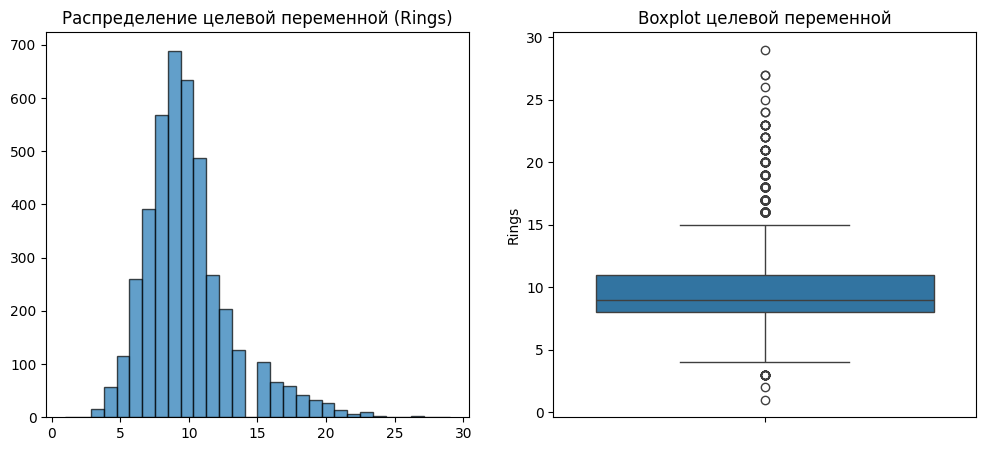

In [12]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['Rings'], bins=30, edgecolor='black', alpha=0.7)
plt.title('Распределение целевой переменной (Rings)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['Rings'])
plt.title('Boxplot целевой переменной')

plt.show()

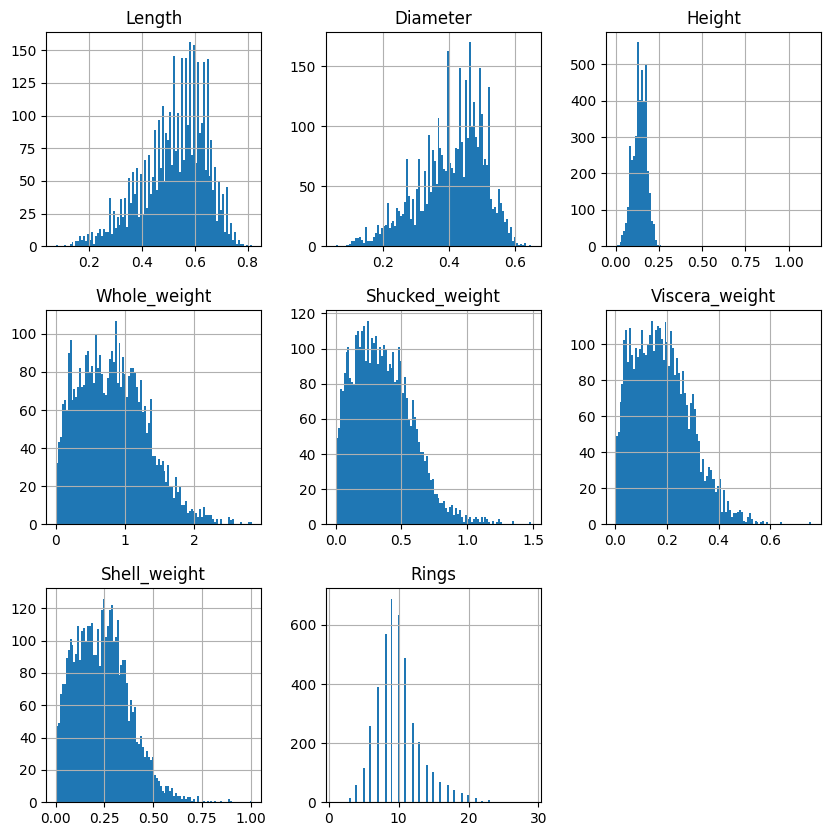

In [13]:
df[['Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight','Viscera_weight', 'Shell_weight', 'Rings']].hist(bins=100, figsize=(10,10));

Распределение Rings похоже на нормальное, но со смещением. Длинный хвост вправо. Большинство имеют средний возраст около 10 колец. Выбросы - редкие случаи (взрослые особи).

Удалим те строки, где значение Rings встречается реже чем в 5% случаев

In [14]:
df1 = df[df['Rings'].map(df['Rings'].value_counts(normalize=True)) >= 0.05]
df1

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7
5,I,0.425,0.300,0.095,0.3515,0.1410,0.0775,0.1200,8
...,...,...,...,...,...,...,...,...,...
4172,F,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11
4173,M,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10
4174,M,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9
4175,F,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10


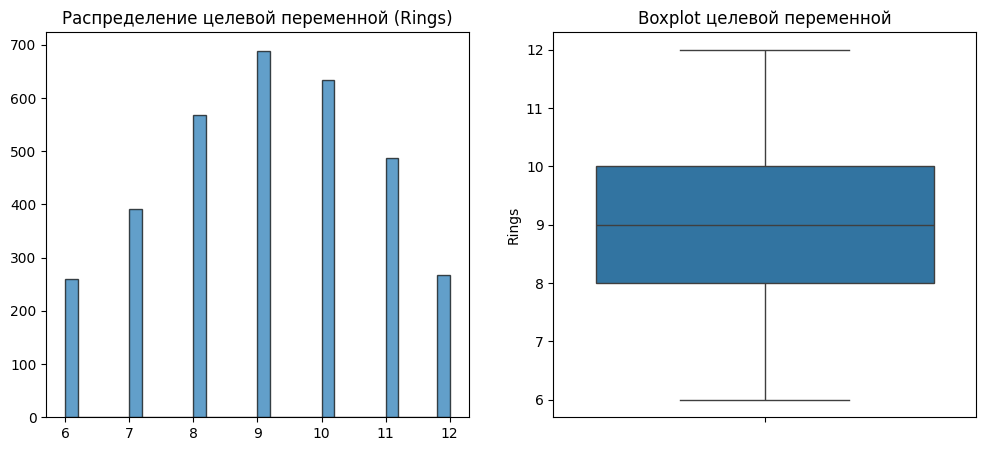

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df1['Rings'], bins=30, edgecolor='black', alpha=0.7)
plt.title('Распределение целевой переменной (Rings)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df1['Rings'])
plt.title('Boxplot целевой переменной')

plt.show()

Пол

In [16]:
df1['Sex'].value_counts(normalize=True)

,proportion
Sex,
M,0.362367
I,0.335357
F,0.302276


Распределение по полу (М, Ж, молодая особь) почти равномерное

Средний возраст по полу

In [17]:
df1.groupby('Sex')['Rings'].agg(['mean', 'median','count'])

,mean,median,count
Sex,,,
F,9.777108,10.0,996
I,7.934842,8.0,1105
M,9.573702,10.0,1194


/tmp/ipykernel_4727/2549768750.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Rings', data = df1, palette='summer')


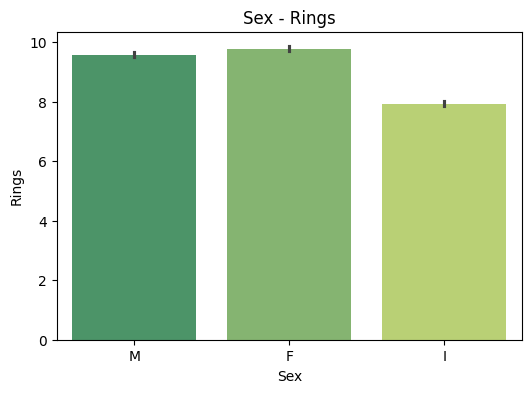

In [18]:
plt.figure(figsize=(6,4))

sns.barplot(x='Sex', y='Rings', data = df1, palette='summer')
plt.title('Sex - Rings')
plt.show();

Средний возраст женщин - наибольший, но почти равен ср. возрасту мужчин. Возраст молодых особей меньше (логично).

Медианный возрат у М и Ж - одинаковый, у молодой особи - меньше.

OneHotEncoder для Sex, т.к. значения не сравнимы.

In [19]:
from sklearn.preprocessing import OneHotEncoder

df_encoded = df.copy()
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
sex_encoded = ohe.fit_transform(df_encoded[['Sex']])
sex_df = pd.DataFrame(sex_encoded, columns=ohe.get_feature_names_out(['Sex'])
)
df_encoded = pd.concat([df_encoded, sex_df], axis=1)
df_encoded = df_encoded.drop('Sex', axis=1)

df_encoded.head()

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Sex_F,Sex_I,Sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,0.0,0.0,1.0
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,0.0,0.0,1.0
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,1.0,0.0,0.0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,0.0,0.0,1.0
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,0.0,1.0,0.0


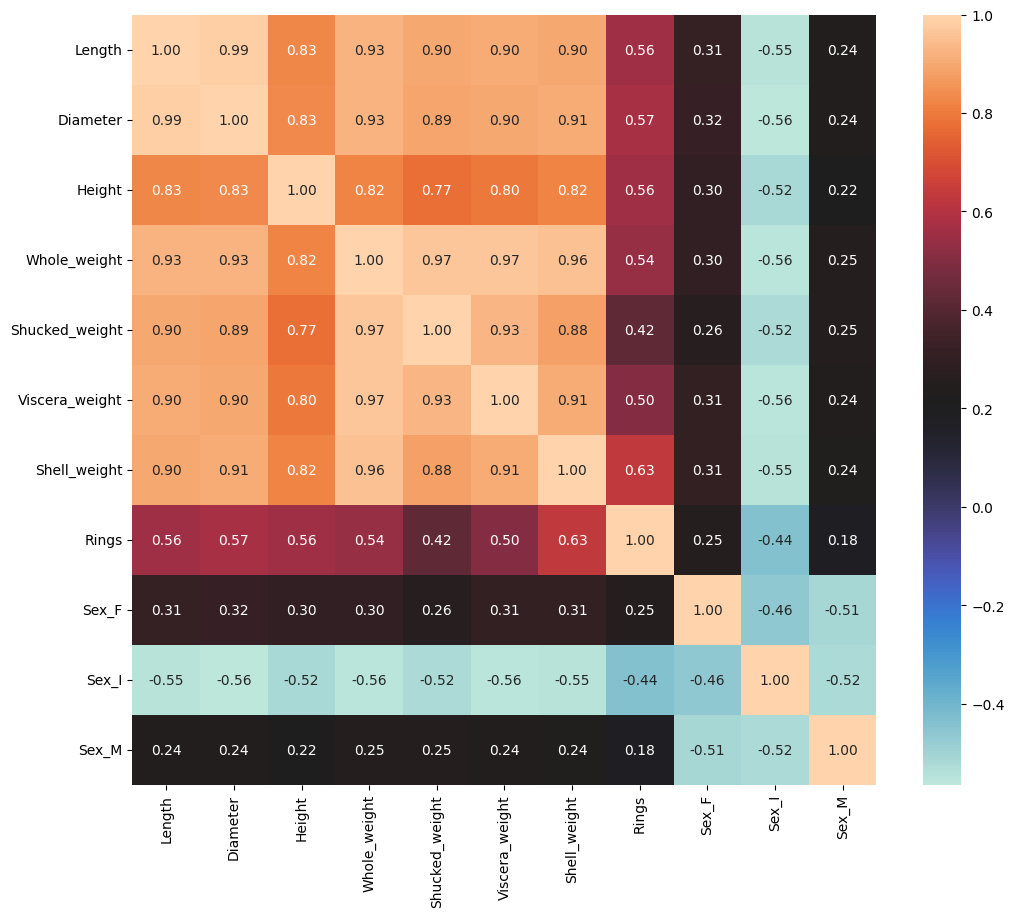

In [20]:
corr_matrix = df_encoded.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='icefire')
plt.show()

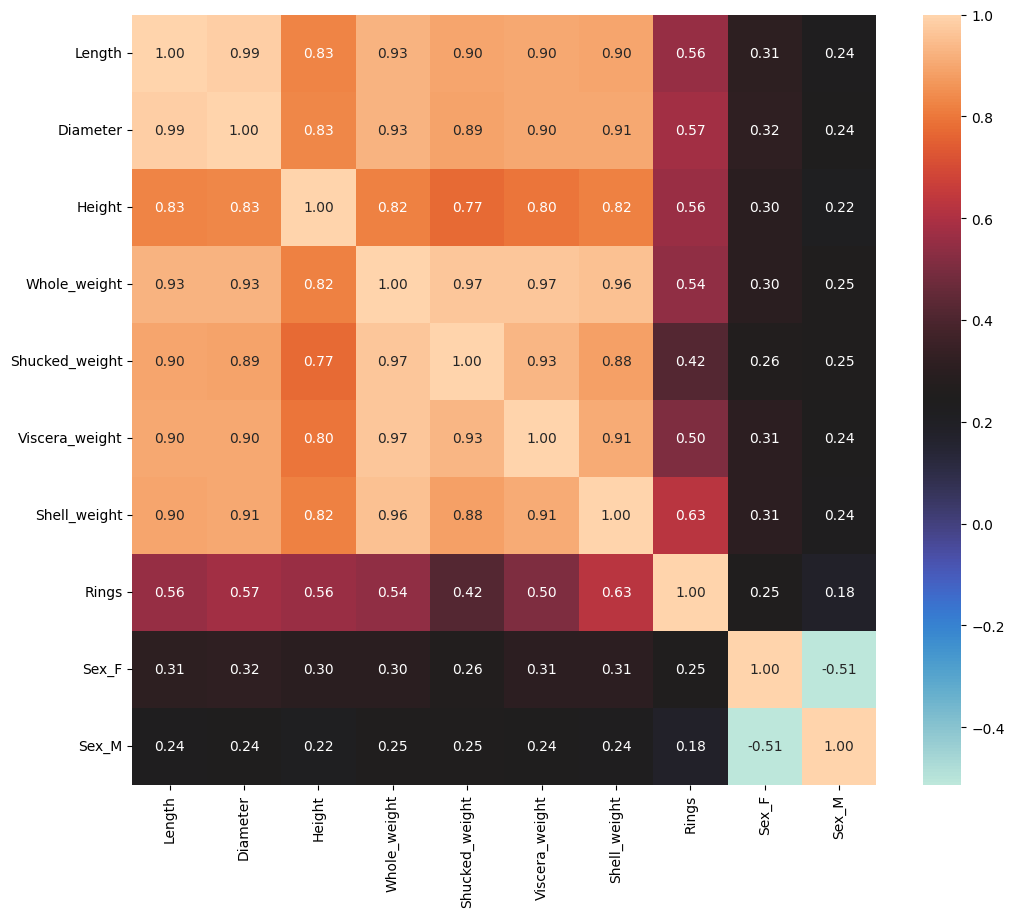

In [21]:
corr_matrix1 = df_encoded.drop(['Sex_I'], axis=1).corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix1, annot=True, fmt='.2f', cmap='icefire')
plt.show()

Наибольшая корреляция Rings c весовыми и геометрическими хар-ками, при этом многие признаки сильно коррелируют друг с другом (например, Length и Diameter, веса между собой).

In [22]:
corr_matrix3 = df_encoded.corr()['Rings'].drop('Rings').sort_values(key=abs, ascending=False)

corr_matrix3.head(5)

,Rings
Shell_weight,0.627574
Diameter,0.574660
Height,0.557467
Length,0.556720
Whole_weight,0.540390


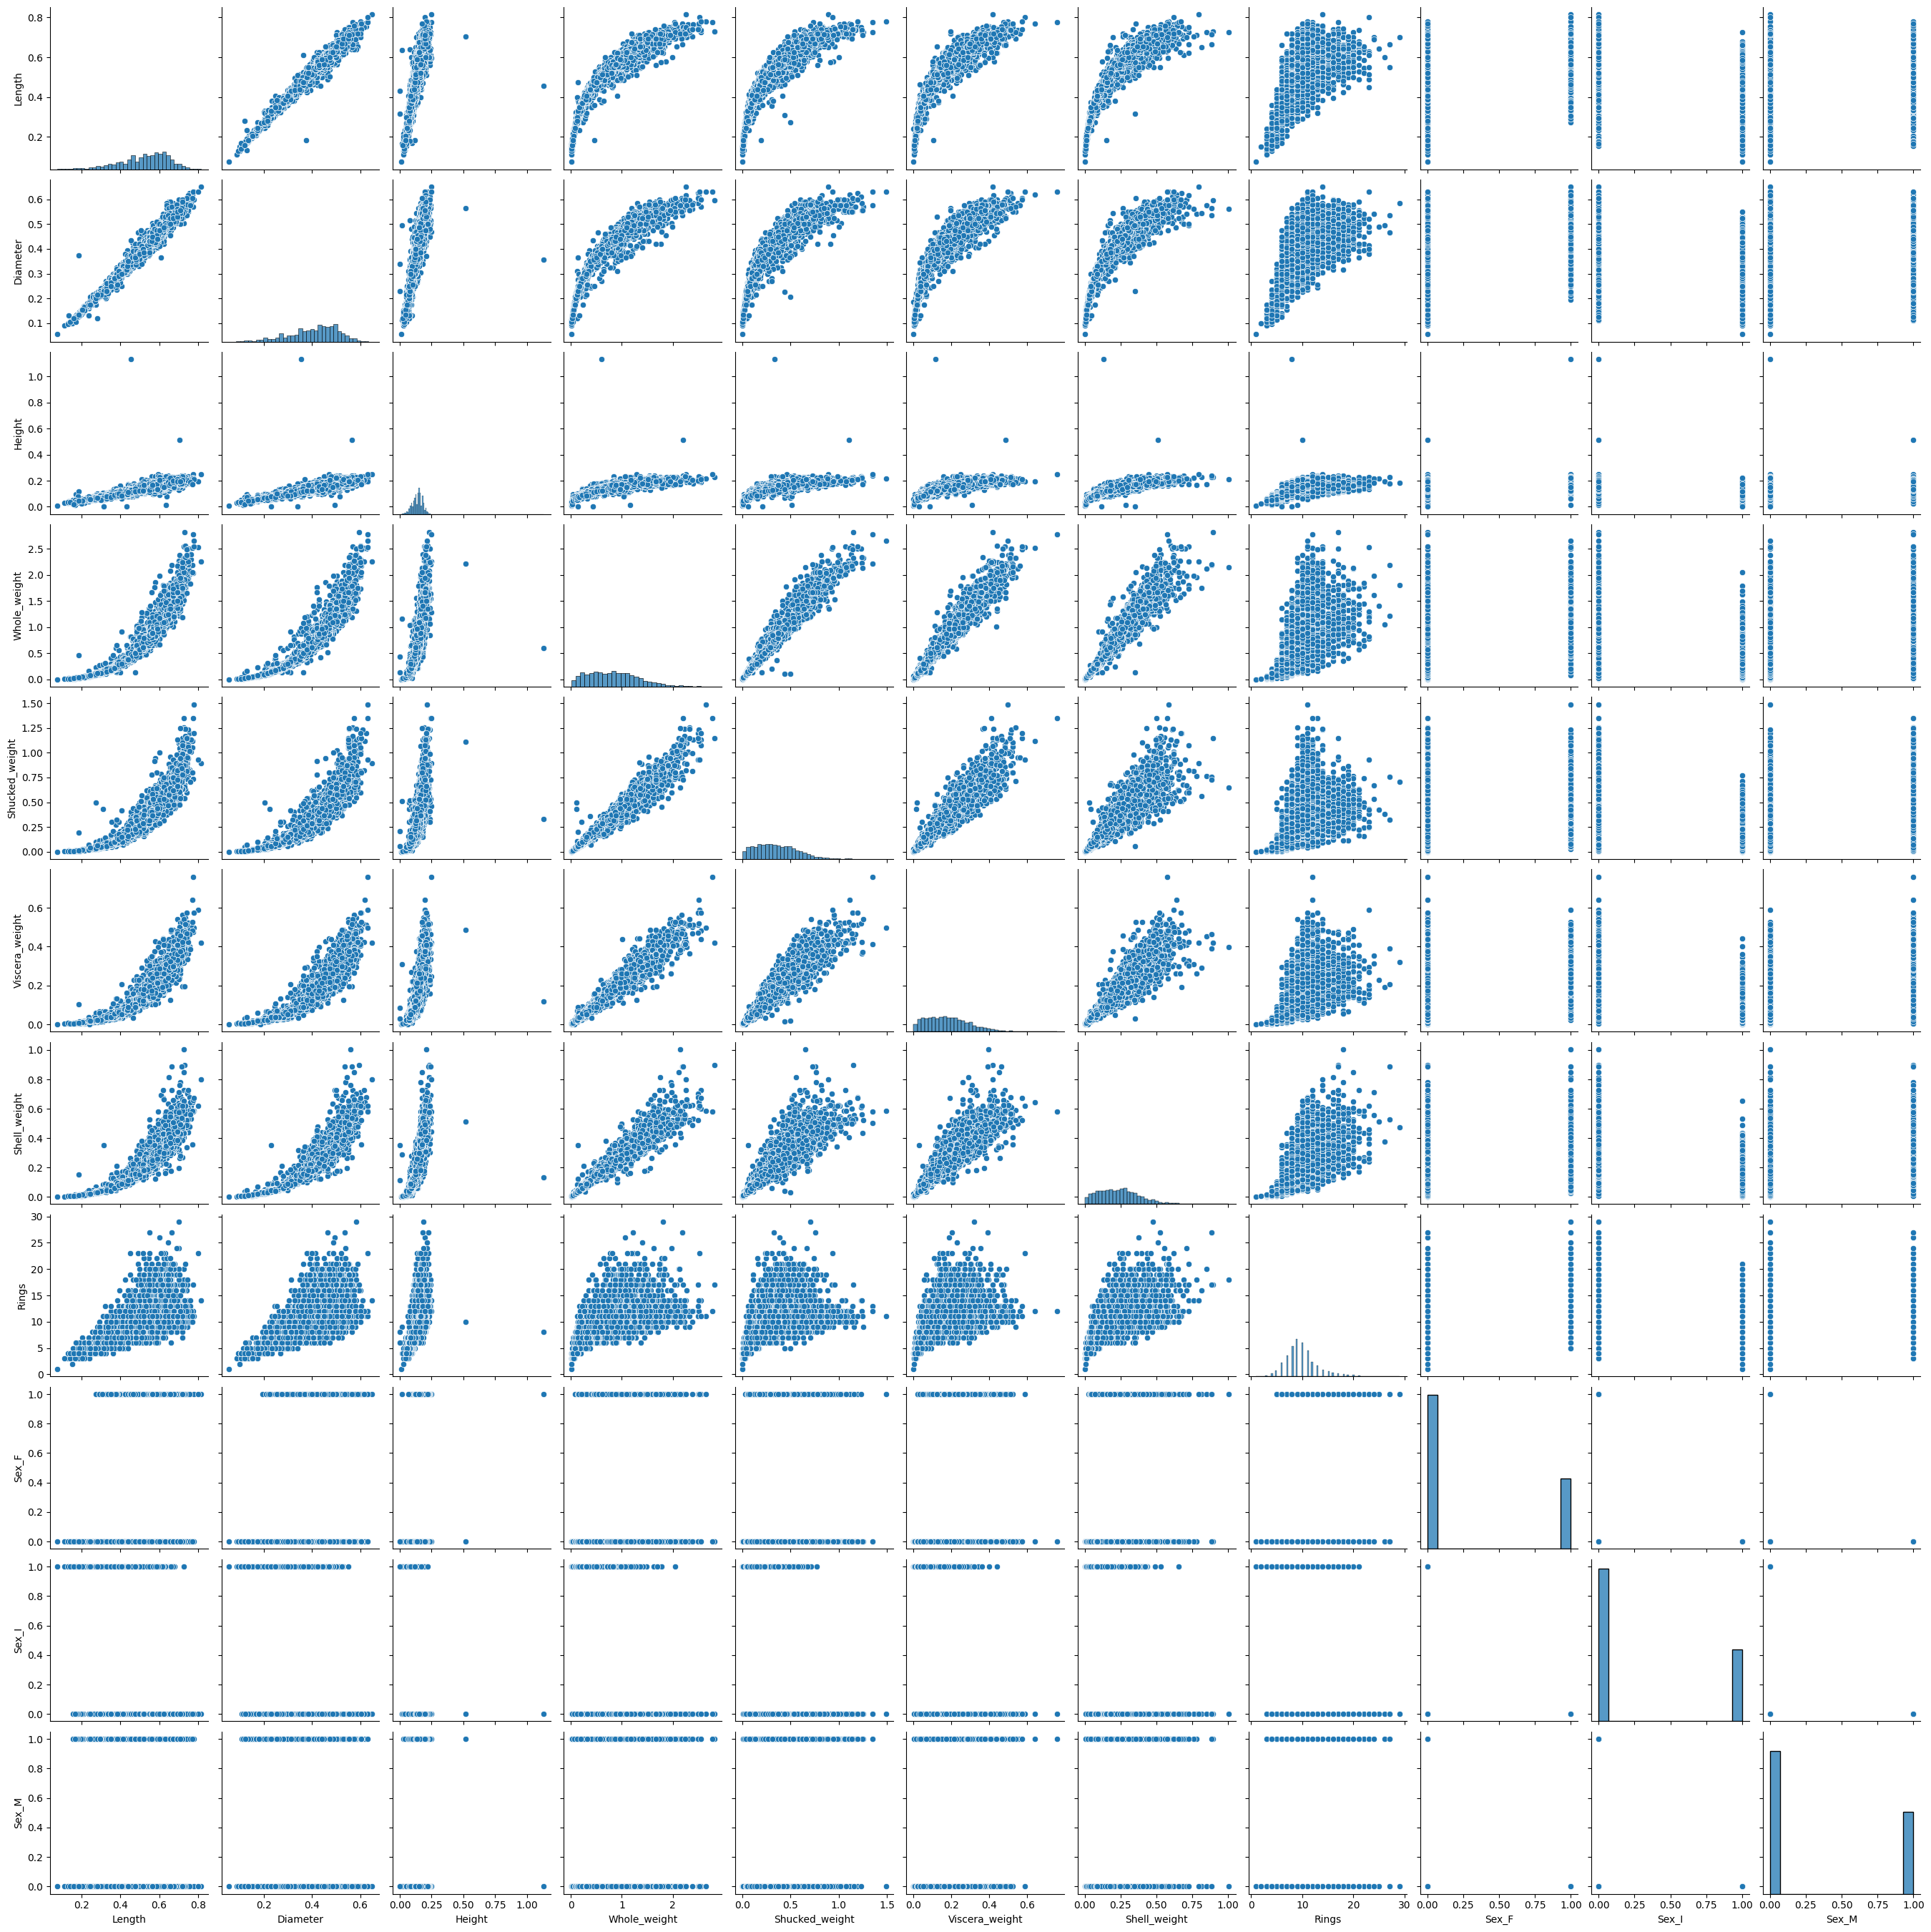

In [23]:
sns.pairplot(df_encoded)

Важность фичей

RandomForestRegressor

In [24]:
df_encoded = df_encoded.dropna()

In [47]:
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

X = df_encoded.drop('Rings', axis=1)
y = df_encoded['Rings']


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

elastic_model = ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=43)
elastic_model.fit(X_scaled, y)

feature_importances_series = pd.DataFrame({
    'feature': X.columns,
    'importance': np.abs(elastic_model.coef_),
    'coef': elastic_model.coef_
}).sort_values(by='importance', ascending=False)

feature_importances_series


,feature,importance,coef
6,Shell_weight,1.823618,1.823618
4,Shucked_weight,1.332816,-1.332816
1,Diameter,0.573057,0.573057
2,Height,0.493033,0.493033
8,Sex_I,0.394197,-0.394197
0,Length,0.107083,0.107083
7,Sex_F,0.003987,0.003987
3,Whole_weight,0.000000,0.000000
5,Viscera_weight,0.000000,-0.000000
9,Sex_M,0.000000,0.000000


In [26]:
from sklearn.inspection import permutation_importance

res = permutation_importance(random_forest, X, y, n_repeats=10, n_jobs=-1, random_state=35)

Лидируют весовые признаки

Shell_weight - абсолютный лидер

Shucked_weight - второй

GradientBoostingRegressor

In [36]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 50.5 MB/s  0:00:01


In [37]:
from catboost import CatBoostRegressor
import pandas as pd

cb_model = CatBoostRegressor(random_seed=43, verbose=0)

X = df_encoded.drop('Rings', axis=1)
y = df_encoded['Rings']

cb_model.fit(X, y)

feature_importances_series = pd.DataFrame({
    'feature': X.columns,
    'importance': cb_model.get_feature_importance()
}).sort_values(by='importance', ascending=False)

feature_importances_series


,feature,importance
6,Shell_weight,30.870772
4,Shucked_weight,23.732714
3,Whole_weight,10.564555
5,Viscera_weight,8.157457
2,Height,7.907552
1,Diameter,6.895709
0,Length,6.456214
8,Sex_I,3.588484
7,Sex_F,1.007891
9,Sex_M,0.818651


In [38]:
from sklearn.inspection import permutation_importance

res1 = permutation_importance(cb_model, X, y, n_repeats=10, n_jobs=1, random_state=35)

In [39]:
from sklearn.inspection import permutation_importance
import pandas as pd

res1 = permutation_importance(
    cb_model,
    X,
    y,
    n_repeats=10,
    n_jobs=1,
    random_state=35
)

res_importance_df1 = pd.DataFrame({
    'feature': X.columns,
    'importance_mean': res1.importances_mean,
    'importance_std': res1.importances_std
}).sort_values('importance_mean', ascending=False)

print(res_importance_df1)


          feature  importance_mean  importance_std
3    Whole_weight         1.346085        0.019019
4  Shucked_weight         1.325657        0.014180
6    Shell_weight         0.504322        0.008081
5  Viscera_weight         0.161996        0.003598
1        Diameter         0.151641        0.003272
2          Height         0.115214        0.002521
0          Length         0.104778        0.003326
8           Sex_I         0.042965        0.002571
7           Sex_F         0.007145        0.000473
9           Sex_M         0.006612        0.000359


Whole_weight — первый
Shucked_weight — второй
Shell_weight — третий (с заметным отрывом от лидеров)


#Настройка моделей

По распределению целевой переменной выделим 3 группы - до 8 колец, с 8 до 9, и свыше 10 колец

In [40]:
y_bins = np.zeros(len(y))
y_bins[y < 8] = 0
y_bins[(y >= 8) & (y < 10)] = 1
y_bins[y >= 10] = 2

In [49]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from catboost import CatBoostRegressor

def evaluate_models_on_dataset(X, y, y_bins, test_size=0.2, random_state=43):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state,
        stratify=y_bins
    )

    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    en_param_grid = {
        'alpha': [0.001, 0.01, 0.1, 1.0, 10.0],
        'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
    }
    en = ElasticNet(max_iter=5000, random_state=random_state)
    en_search = GridSearchCV(
        en, en_param_grid, cv=3,
        scoring='neg_mean_squared_error', n_jobs=-1
    )
    en_search.fit(X_train_scaled, y_train)

    cb_param_grid = {
        'iterations': (200, 500),
        'depth': (4, 6),
        'learning_rate': [0.03, 0.1]
    }
    cb = CatBoostRegressor(random_seed=random_state, verbose=0, thread_count=-1)
    cb_search = GridSearchCV(
        cb, cb_param_grid, cv=3,
        scoring='neg_mean_squared_error', n_jobs=1
    )
    cb_search.fit(X_train_scaled, y_train)

    searches = {
        'ElasticNet': en_search,
        'CatBoost': cb_search
    }

    results = {}

    for name, search in searches.items():
        model = search.best_estimator_
        y_pred = model.predict(X_test_scaled)

        mse = mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        mape = mean_absolute_percentage_error(y_test, y_pred)

        results[name] = {
            'model': model,
            'mse': mse,
            'r2': r2,
            'mape': mape,
            'y_pred': y_pred,
            'best_params': search.best_params_
        }

        print(f"\nМодель: {name}")
        print(f"MSE: {mse:.4f}")
        print(f"R^2: {r2:.4f}")
        print(f"MAPE: {mape:.4f}")
        print(f"Лучшие параметры: {search.best_params_}")

    return results


На всех фичах

In [48]:
results = evaluate_models_on_dataset(X, y, y_bins)


Модель: ElasticNet
MSE: 5.1195
R^2: 0.4911
MAPE: 0.1673
Лучшие параметры: {'alpha': 0.001, 'l1_ratio': 0.9}

Модель: CatBoost
MSE: 4.5755
R^2: 0.5451
MAPE: 0.1528
Лучшие параметры: {'depth': 6, 'iterations': 500, 'learning_rate': 0.03}


Удалим Sex

In [50]:
X1 = X.drop(['Sex_F', 'Sex_M','Sex_I'],axis=1)
results1 = evaluate_models_on_dataset(X1, y, y_bins)


Модель: ElasticNet
MSE: 5.3193
R^2: 0.4712
MAPE: 0.1705
Лучшие параметры: {'alpha': 0.001, 'l1_ratio': 0.9}

Модель: CatBoost
MSE: 4.6553
R^2: 0.5372
MAPE: 0.1542
Лучшие параметры: {'depth': 6, 'iterations': 200, 'learning_rate': 0.1}


На топ-2 самых важных признаках

In [51]:
X2 = df_encoded[['Shell_weight', 'Shucked_weight']]
results2 = evaluate_models_on_dataset(X2, y, y_bins)


Модель: ElasticNet
MSE: 5.4807
R^2: 0.4552
MAPE: 0.1827
Лучшие параметры: {'alpha': 0.001, 'l1_ratio': 0.9}

Модель: CatBoost
MSE: 4.8120
R^2: 0.5216
MAPE: 0.1579
Лучшие параметры: {'depth': 4, 'iterations': 500, 'learning_rate': 0.03}


Сводная таблица

In [52]:
def add_res(results_dict, dataset_name, all_rows):
    for model_name, model_results in results_dict.items():
        row = {
            'Dataset': dataset_name,
            'Model': model_name,
            'MSE': model_results['mse'],
            'R2': model_results['r2'],
            'MAPE': model_results['mape']
        }
        for param_name, param_value in model_results['best_params'].items():
            row[param_name] = param_value

        all_rows.append(row)

all_rows = []
add_res(results, 'X', all_rows)
add_res(results1, 'X1', all_rows)
add_res(results2, 'X2', all_rows)

summary_df = pd.DataFrame(all_rows)
summary_df.sort_values('R2', ascending=False)

,Dataset,Model,MSE,R2,MAPE,alpha,l1_ratio,depth,iterations,learning_rate
1,X,CatBoost,4.575476,0.545149,0.152754,NaN,NaN,6.0,500.0,0.03
3,X1,CatBoost,4.655281,0.537215,0.154188,NaN,NaN,6.0,200.0,0.10
5,X2,CatBoost,4.812038,0.521632,0.157863,NaN,NaN,4.0,500.0,0.03
0,X,ElasticNet,5.119462,0.491071,0.167292,0.001,0.9,NaN,NaN,NaN
2,X1,ElasticNet,5.319279,0.471207,0.170541,0.001,0.9,NaN,NaN,NaN
4,X2,ElasticNet,5.480713,0.455158,0.182680,0.001,0.9,NaN,NaN,NaN


catboost показал лучшие результаты по сравнению с elasticnet на всех трех датасетах, но разница R^2 небольшая. Наилучшие показатели достигнуты на исходном датасете X, который включает все фичи. Но значение R^2 все равно плохое, что объясняется проблемой датасета - после достижения зрелости рост размеров и массы моллюска замедляется, тогда как количество колец продолжает расти